# Gold Price Movement Prediction (Classification)

Bu projede, geçmiş gram altın/TL fiyatlarından yararlanarak bir sonraki kayıtta fiyatın yükselip yükselmeyeceğini tahmin ediyoruz. Logistic Regression ve Random Forest modellerini, her zaman yükseliş tahmini yapan bir yöntemle karşılaştırıyoruz.

## 1. Veri setini yükleme

In [32]:
import pandas as pd

dosya = "Data/gold_try.csv"

try:
    df = pd.read_csv(dosya, sep=None, engine="python", encoding="utf-8-sig", dtype=str)
except UnicodeDecodeError:
    df = pd.read_csv(dosya, sep=None, engine="python", encoding="cp1254", dtype=str)

print("Satır ve sütun sayısı:", df.shape)
print("Sütun adları:", df.columns.tolist())
display(df.head())

Satır ve sütun sayısı: (1279, 7)
Sütun adları: ['Tarih', 'Şimdi', 'Açılış', 'Yüksek', 'Düşük', 'Hac.', 'Fark %']


,Tarih,Şimdi,Açılış,Yüksek,Düşük,Hac.,Fark %
0,30.06.2025,"4.198,131","4.186,547","4.229,386","4.181,488",NaN,"0,27%"
1,29.06.2025,"4.187,025","4.207,394","4.207,394","4.166,662",NaN,"-0,31%"
2,27.06.2025,"4.200,042","4.249,853","4.252,019","4.175,443",NaN,"-1,29%"
3,26.06.2025,"4.254,756","4.261,735","4.284,807","4.233,000",NaN,"-0,35%"
4,25.06.2025,"4.269,573","4.238,524","4.269,772","4.233,082",NaN,"0,72%"


## 2. Tarih ve fiyatları temizleme

In [33]:
veri = df[["Tarih", "Şimdi"]].copy()
veri.columns = ["tarih", "fiyat_tl"]

veri["tarih"] = pd.to_datetime(veri["tarih"], format="%d.%m.%Y")

# Örnek: "4.198,131" → 4198.131
fiyat_metni = (
    veri["fiyat_tl"]
    .str.strip()
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)
veri["fiyat_tl"] = pd.to_numeric(fiyat_metni)

# Bir sonraki kaydı doğru belirlemek için tarihleri eskiden yeniye sırala.
veri = veri.sort_values("tarih").reset_index(drop=True)

print("Toplam kayıt:", len(veri))
print("İlk tarih:", veri["tarih"].min().date())
print("Son tarih:", veri["tarih"].max().date())
print("Eksik tarih:", veri["tarih"].isna().sum())
print("Eksik fiyat:", veri["fiyat_tl"].isna().sum())
print("Tekrarlanan tarih:", veri["tarih"].duplicated().sum())

display(veri.tail(3))

Toplam kayıt: 1279
İlk tarih: 2021-01-31
Son tarih: 2025-06-30
Eksik tarih: 0
Eksik fiyat: 0
Tekrarlanan tarih: 0


,tarih,fiyat_tl
1276,2025-06-27,4200.042
1277,2025-06-29,4187.025
1278,2025-06-30,4198.131


## 3. Hedef değişken: Bir sonraki kayıtta fiyat yükseldi mi?

In [34]:
sonraki_fiyat = veri["fiyat_tl"].shift(-1)

# 1 = yükseldi, 0 = düştü veya sabit kaldı.
veri["yukseldi"] = (sonraki_fiyat > veri["fiyat_tl"]).astype("Int64")

# Son kaydın ardından fiyat bilinmediği için doğru cevap da bilinmiyor.
veri.loc[sonraki_fiyat.isna(), "yukseldi"] = pd.NA

print("Etiketi bilinen kayıt:", veri["yukseldi"].count())

kontrol = veri[["tarih", "fiyat_tl", "yukseldi"]].copy()
kontrol.insert(2, "sonraki_fiyat_tl", sonraki_fiyat)
display(kontrol.tail(3))

Etiketi bilinen kayıt: 1278


,tarih,fiyat_tl,sonraki_fiyat_tl,yukseldi
1276,2025-06-27,4200.042,4187.025,0
1277,2025-06-29,4187.025,4198.131,1
1278,2025-06-30,4198.131,NaN,<NA>


## 4. Geçmiş fiyatlardan özellik üretme

In [35]:
fiyat = veri["fiyat_tl"]

# Mevcut fiyatın bir ve beş kayıt öncesine göre yüzde değişimi.
veri["degisim_1"] = fiyat.pct_change(1) * 100
veri["degisim_5"] = fiyat.pct_change(5) * 100

# Mevcut fiyatın, bugün dahil son on kaydın ortalamasına uzaklığı.
ortalama_10 = fiyat.rolling(window=10).mean()
veri["ortalamadan_fark_10"] = (fiyat / ortalama_10 - 1) * 100

ozellikler = ["degisim_1", "degisim_5", "ortalamadan_fark_10"]
model_verisi = veri.dropna(subset=ozellikler + ["yukseldi"]).copy()

print("Model için hazır kayıt:", len(model_verisi))
display(model_verisi[["tarih", *ozellikler, "yukseldi"]].tail(5))

Model için hazır kayıt: 1269


,tarih,degisim_1,degisim_5,ortalamadan_fark_10,yukseldi
1273,2025-06-24,-0.810368,-1.123686,-1.487157,1
1274,2025-06-25,0.715791,-0.650421,-0.596807,0
1275,2025-06-26,-0.347037,-0.970683,-0.669869,0
1276,2025-06-27,-1.285949,-2.518299,-1.710262,0
1277,2025-06-29,-0.309925,-2.031839,-1.746296,1


## 5. Eğitim ve test dönemlerinin ayrılması

In [36]:
sinir = int(len(model_verisi) * 0.80)

# Sınırdaki tek kaydın etiketi ilk test fiyatına bağlı olduğu için onu ayır.
egitim = model_verisi.iloc[:sinir - 1].copy()
test = model_verisi.iloc[sinir:].copy()

X_train = egitim[ozellikler]
y_train = egitim["yukseldi"].astype(int)

X_test = test[ozellikler]
y_test = test["yukseldi"].astype(int)

for ad, bolum in [("Eğitim", egitim), ("Test", test)]:
    ilk_tarih = bolum["tarih"].iloc[0].date()
    son_tarih = bolum["tarih"].iloc[-1].date()
    print(f"{ad}: {len(bolum)} kayıt | {ilk_tarih} → {son_tarih}")

Eğitim: 1014 kayıt | 2021-02-10 → 2024-07-15
Test: 254 kayıt | 2024-07-17 → 2025-06-29


## 6. Logistic Regression ve Random Forest modellerinin eğitimi

In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modeller = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=10,
        random_state=42
    )
}

for ad, model in modeller.items():
    model.fit(X_train, y_train)
    print(f"{ad} eğitildi.")

Logistic Regression eğitildi.
Random Forest eğitildi.


## 7. Modellerin test sonuçları

In [38]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

tahminler = {"Her zaman yükselir": [1] * len(y_test)}

for ad, model in modeller.items():
    tahminler[ad] = model.predict(X_test)

sonuclar = []

for ad, tahmin in tahminler.items():
    matris = confusion_matrix(y_test, tahmin, labels=[0, 1])
    dogru_dusus_sabit = matris[0, 0]
    dogru_yukselis = matris[1, 1]

    sonuclar.append({
        "Yöntem": ad,
        "Doğru tahmin": dogru_dusus_sabit + dogru_yukselis,
        "Doğruluk (%)": 100 * accuracy_score(y_test, tahmin),
        "Dengeli doğruluk (%)": 100 * balanced_accuracy_score(y_test, tahmin),
        "Doğru yükseliş": dogru_yukselis,
        "Doğru düşüş/sabit": dogru_dusus_sabit
    })

sonuc_tablosu = pd.DataFrame(sonuclar).set_index("Yöntem").round(2)
display(sonuc_tablosu)

,Doğru tahmin,Doğruluk (%),Dengeli doğruluk (%),Doğru yükseliş,Doğru düşüş/sabit
Yöntem,,,,,
Her zaman yükselir,148,58.27,50.00,148,0
Logistic Regression,148,58.27,50.00,148,0
Random Forest,150,59.06,52.28,138,12


## 8. Son sekiz tahminde model ne dedi, fiyat ne yaptı?

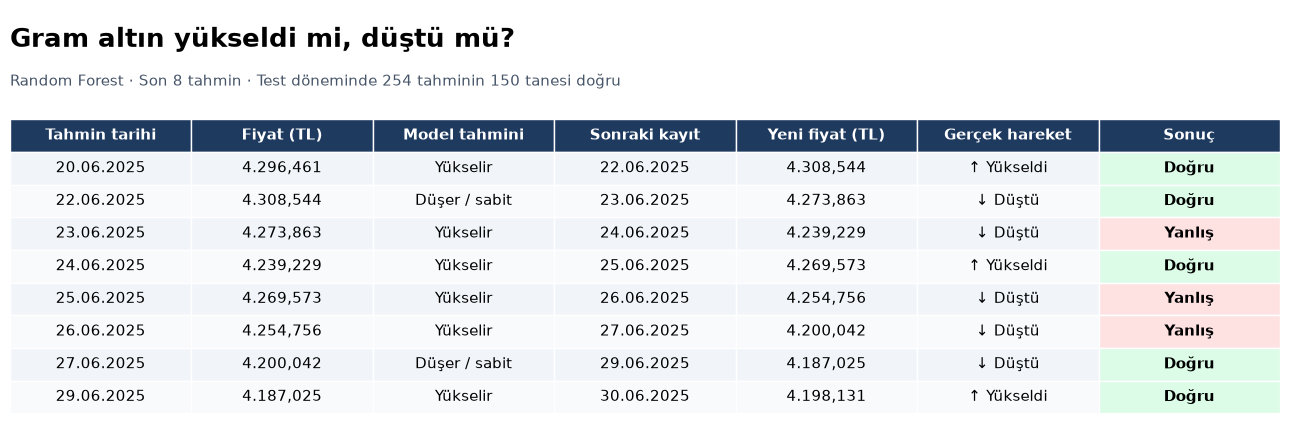

In [39]:
import matplotlib.pyplot as plt

kayitlar = test[["tarih", "fiyat_tl"]].copy()
kayitlar["sonraki_tarih"] = veri["tarih"].shift(-1).reindex(test.index)
kayitlar["sonraki_fiyat"] = sonraki_fiyat.reindex(test.index)
kayitlar["tahmin"] = tahminler["Random Forest"]
kayitlar["dogru"] = kayitlar["tahmin"].eq(y_test)


def fiyat_yaz(fiyat):
    return f"{fiyat:,.3f}".translate(str.maketrans(",.", ".,"))


satirlar = []

for kayit in kayitlar.tail(8).itertuples():
    if kayit.sonraki_fiyat > kayit.fiyat_tl:
        gercek_hareket = "↑ Yükseldi"
    elif kayit.sonraki_fiyat < kayit.fiyat_tl:
        gercek_hareket = "↓ Düştü"
    else:
        gercek_hareket = "→ Sabit kaldı"

    satirlar.append([
        kayit.tarih.strftime("%d.%m.%Y"),
        fiyat_yaz(kayit.fiyat_tl),
        "Yükselir" if kayit.tahmin == 1 else "Düşer / sabit",
        kayit.sonraki_tarih.strftime("%d.%m.%Y"),
        fiyat_yaz(kayit.sonraki_fiyat),
        gercek_hareket,
        "Doğru" if kayit.dogru else "Yanlış"
    ])

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.axis("off")

ax.text(
    0, 0.96, "Gram altın yükseldi mi, düştü mü?",
    transform=ax.transAxes, fontsize=19, weight="bold", va="top"
)

dogru_sayisi = kayitlar["dogru"].sum()
ax.text(
    0, 0.82,
    f"Random Forest · Son 8 tahmin · Test döneminde "
    f"{len(kayitlar)} tahminin {dogru_sayisi} tanesi doğru",
    transform=ax.transAxes, fontsize=11, color="#475569"
)

tablo = ax.table(
    cellText=satirlar,
    colLabels=[
        "Tahmin tarihi", "Fiyat (TL)", "Model tahmini",
        "Sonraki kayıt", "Yeni fiyat (TL)", "Gerçek hareket", "Sonuç"
    ],
    cellLoc="center",
    bbox=[0, 0.04, 1, 0.70]
)
tablo.auto_set_font_size(False)
tablo.set_fontsize(11)

for (satir, sutun), hucre in tablo.get_celld().items():
    hucre.set_edgecolor("white")

    if satir == 0:
        hucre.set_facecolor("#1e3a5f")
        hucre.set_text_props(color="white", weight="bold")
    elif sutun == 6:
        dogru_mu = satirlar[satir - 1][-1] == "Doğru"
        hucre.set_facecolor("#dcfce7" if dogru_mu else "#fee2e2")
        hucre.set_text_props(weight="bold")
    else:
        hucre.set_facecolor("#f1f5f9" if satir % 2 else "#f8fafc")

fig.tight_layout()
plt.show()